# Lab 02 · NumPy for Numerical Computing (Solved)
**CS-3105 Machine Learning Lab**

Name: ______  Roll No: ______

### Datasets (run this cell first, do not edit)

In [56]:
import numpy as np

# ===================== DATASETS (given to students in the starter notebook) =====================
# D1. Population Census 2023 (PBS), source: 2023 Pakistani census results
units = np.array(["Punjab", "Sindh", "Khyber Pakhtunkhwa", "Balochistan", "Islamabad", "AJK", "Gilgit-Baltistan"])
pop_2023 = np.array([127_688_922, 55_696_147, 40_856_097, 14_894_402, 2_363_863, 4_333_467, 1_709_049])
pop_2017 = np.array([109_989_655, 47_854_510, 35_501_964, 12_335_129, 2_003_368, 4_045_367, 1_492_924])

# D2. Climate normals 1991-2020 (PMD / WMO), mean daily maximum temperature (°C) and rainfall (mm)
cities = np.array(["Lahore", "Karachi", "Islamabad", "Peshawar", "Quetta"])
months = np.array(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
tmax = np.array([
    [18.4, 22.2, 27.5, 34.2, 38.9, 38.9, 35.6, 34.7, 34.4, 32.4, 27.1, 21.4],   # Lahore
    [26.3, 28.7, 32.6, 35.0, 35.7, 35.7, 33.6, 32.5, 33.4, 35.6, 32.6, 28.4],   # Karachi
    [17.7, 20.0, 24.8, 30.6, 36.1, 38.3, 35.4, 33.9, 33.4, 30.9, 25.4, 20.4],   # Islamabad
    [18.1, 20.1, 24.7, 30.6, 36.5, 39.6, 37.4, 35.9, 34.8, 31.0, 25.2, 20.6],   # Peshawar
    [11.8, 14.0, 19.5, 25.9, 31.4, 35.5, 36.8, 35.4, 31.9, 26.0, 19.6, 14.6]])  # Quetta
rain = np.array([
    [21.9, 31.5, 31.5, 19.5, 17.7, 73.8, 188.6, 177.1, 88.6, 10.3, 6.9, 6.8],
    [10.6, 5.5, 3.2, 11.1, 9.2, 24.6, 86.1, 104.7, 44.0, 12.7, 0.7, 5.6],
    [55.2, 93.4, 95.2, 58.1, 39.9, 78.4, 310.6, 317.0, 135.4, 34.4, 17.7, 25.9],
    [39.8, 69.9, 78.2, 68.1, 26.7, 25.4, 69.0, 68.5, 34.8, 26.7, 16.9, 17.3],
    [55.0, 58.4, 49.5, 40.0, 17.8, 3.2, 8.8, 4.9, 4.2, 4.5, 19.3, 34.6]])

# D3. CPI inflation, year-on-year % (Pakistan Economic Survey 2024-25, Fig 7.1, from PBS)
cpi_months = np.array(["Jul", "Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr"])
cpi = np.array([[28.3, 27.4, 31.4, 26.8, 29.2, 29.7, 28.3, 23.1, 20.7, 17.3],    # FY2024
                [11.1,  9.6,  6.9,  7.2,  4.9,  4.1,  2.4,  1.5,  0.7,  0.3]])   # FY2025

# D4. Marks of one lab section (sample class data)
marks = np.array([45, 78, 92, 38, 66, 97, 49, 55, 71, 83])

## Task 1 · Setup

In [57]:
# T1: import NumPy (already done in the datasets cell, repeated here for clarity)
import numpy as np
print("T1:", np.__version__)

T1: 2.5.4


## Task 2 · Class register: creating arrays

In [58]:
# T2: creating arrays
attendance = np.zeros(10)                 # (a) 10 zeros
fee_paid   = np.ones(10)                  # (b) 10 ones
grace      = np.full(10, 5)               # (c) ten 5s
rolls_all  = np.arange(10, 51)            # (d) 10..50 inclusive (stop is exclusive, so use 51)
rolls_even = np.arange(10, 51, 2)         # (e) step of 2 gives even numbers
seat_map   = np.arange(9).reshape(3, 3)   # (f) values 0..8 as a 3x3 grid
identity   = np.eye(3)                    # (g) 3x3 identity matrix

print("T2a:", attendance)
print("T2b:", fee_paid)
print("T2c:", grace)
print("T2d:", rolls_all)
print("T2e:", rolls_even)
print("T2f:\n", seat_map)
print("T2g:\n", identity)

T2a: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
T2b: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
T2c: [5 5 5 5 5 5 5 5 5 5]
T2d: [10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33
 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50]
T2e: [10 12 14 16 18 20 22 24 26 28 30 32 34 36 38 40 42 44 46 48 50]
T2f:
 [[0 1 2]
 [3 4 5]
 [6 7 8]]
T2g:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


## Task 3 · Randomness and reproducibility

In [59]:
# T3: randomness and reproducibility
np.random.seed(2026)
print("T3a:", np.random.rand())                      # (a) one number in [0, 1)

normal_25 = np.random.randn(25)                      # (b) 25 standard-normal numbers
print("T3b:", np.round(normal_25, 3))

np.random.seed(42)
dice = np.random.randint(1, 7, size=10_000)          # (c) 10,000 rolls (high is exclusive, so 7)
faces, counts = np.unique(dice, return_counts=True)
print("T3c: faces =", faces, "counts =", counts)

p_six = np.mean(dice == 6)                           # (d) True counts as 1, so the mean is a fraction
print("T3d: P(six) =", p_six, "| 1/6 =", round(1/6, 4), "| difference =", round(abs(p_six - 1/6), 4))

# (e) two sixes in a row: compare each roll with the next one, no loop needed
double_six = np.sum((dice[:-1] == 6) & (dice[1:] == 6))
print("T3e: back-to-back sixes =", double_six, "| expected about", round(9999 / 36))

T3a: 0.21934563492692294
T3b: [ 0.349 -0.064 -0.044 -0.881  0.12   0.85  -0.696  0.998 -1.581 -0.796
  2.006 -1.781  1.413 -0.99  -0.316 -0.447 -1.256  0.68  -0.04  -0.62
  0.747  0.36   0.22   1.987 -1.675]
T3c: faces = [1 2 3 4 5 6] counts = [1665 1692 1625 1672 1689 1657]
T3d: P(six) = 0.1657 | 1/6 = 0.1667 | difference = 0.001
T3e: back-to-back sixes = 265 | expected about 278


## Task 4 · Spacing and reshaping

In [60]:
# T4: spacing and reshaping
grid = np.linspace(0.01, 1.00, 100).reshape(10, 10)  # (a) 100 values from 0.01 to 1.00
print("T4a:\n", np.round(grid, 2))

print("T4b:", np.linspace(0, 1, 20))                 # (b) 20 evenly spaced points

lahore_q = rain[0].reshape(4, 3)                     # (c) 4 quarters x 3 months
print("T4c:\n", lahore_q)

q_total = lahore_q.sum(axis=1)                       # (d) sum across the 3 months of each quarter
print("T4d: rain per quarter =", q_total, "| wettest quarter index =", q_total.argmax(),
      "(Q" + str(q_total.argmax() + 1) + ", Jul-Sep)")

T4a:
 [[0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1 ]
 [0.11 0.12 0.13 0.14 0.15 0.16 0.17 0.18 0.19 0.2 ]
 [0.21 0.22 0.23 0.24 0.25 0.26 0.27 0.28 0.29 0.3 ]
 [0.31 0.32 0.33 0.34 0.35 0.36 0.37 0.38 0.39 0.4 ]
 [0.41 0.42 0.43 0.44 0.45 0.46 0.47 0.48 0.49 0.5 ]
 [0.51 0.52 0.53 0.54 0.55 0.56 0.57 0.58 0.59 0.6 ]
 [0.61 0.62 0.63 0.64 0.65 0.66 0.67 0.68 0.69 0.7 ]
 [0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.8 ]
 [0.81 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.9 ]
 [0.91 0.92 0.93 0.94 0.95 0.96 0.97 0.98 0.99 1.  ]]
T4b: [0.         0.05263158 0.10526316 0.15789474 0.21052632 0.26315789
 0.31578947 0.36842105 0.42105263 0.47368421 0.52631579 0.57894737
 0.63157895 0.68421053 0.73684211 0.78947368 0.84210526 0.89473684
 0.94736842 1.        ]
T4c:
 [[ 21.9  31.5  31.5]
 [ 19.5  17.7  73.8]
 [188.6 177.1  88.6]
 [ 10.3   6.9   6.8]]
T4d: rain per quarter = [ 84.9 111.  454.3  24. ] | wettest quarter index = 2 (Q3, Jul-Sep)


## Task 5 · Exam hall seating plan

In [61]:
# T5: exam hall (indexing and slicing)
hall = np.arange(1, 26).reshape(5, 5)
print("hall:\n", hall)

print("T5a:\n", hall[2:, 1:])
# Rows 3-5, columns 2-5: seats 12,13,14,15 / 17,18,19,20 / 22,23,24,25 (bottom-right block)

print("T5b:", hall[3, 4])
# One single seat: row 4, column 5 -> seat 20

print("T5c:\n", hall[0:3, 1:2])
# First 3 rows, only column 2 -> seats 2, 7, 12 (kept as a column)

print("T5d:", hall[4])
# The whole last row -> seats 21 to 25

print("T5e:\n", hall[3:])
# The last two rows -> seats 16 to 25

print("T5f: sum =", hall.sum(), "| std =", round(hall.std(), 4))

hall:
 [[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]
 [21 22 23 24 25]]
T5a:
 [[12 13 14 15]
 [17 18 19 20]
 [22 23 24 25]]
T5b: 20
T5c:
 [[ 2]
 [ 7]
 [12]]
T5d: [21 22 23 24 25]
T5e:
 [[16 17 18 19 20]
 [21 22 23 24 25]]
T5f: sum = 325 | std = 7.2111


## Task 6 · Census 2023

In [62]:
# T6: Census 2023
total = pop_2023.sum()                                        # (a)
print("T6a: total population =", f"{total:,}")

share = pop_2023 / total * 100                                # (b)
for u, s in zip(units, share):
    print(f"T6b: {u:20s} {s:6.2f} %")

print("T6c: most populous =", units[pop_2023.argmax()])       # (c)

print("T6d: more than 20 million =", units[pop_2023 > 20_000_000])  # (d) boolean mask

growth = ((pop_2023 / pop_2017) ** (1/6) - 1) * 100           # (e)
for u, g in zip(units, growth):
    print(f"T6e: {u:20s} {g:5.2f} % per year")

print("T6f: fastest growing =", units[growth.argmax()], "at", round(growth.max(), 2), "%")  # (f)

T6a: total population = 247,541,947
T6b: Punjab                51.58 %
T6b: Sindh                 22.50 %
T6b: Khyber Pakhtunkhwa    16.50 %
T6b: Balochistan            6.02 %
T6b: Islamabad              0.95 %
T6b: AJK                    1.75 %
T6b: Gilgit-Baltistan       0.69 %
T6c: most populous = Punjab
T6d: more than 20 million = ['Punjab' 'Sindh' 'Khyber Pakhtunkhwa']
T6e: Punjab                2.52 % per year
T6e: Sindh                 2.56 % per year
T6e: Khyber Pakhtunkhwa    2.37 % per year
T6e: Balochistan           3.19 % per year
T6e: Islamabad             2.80 % per year
T6e: AJK                   1.15 % per year
T6e: Gilgit-Baltistan      2.28 % per year
T6f: fastest growing = Balochistan at 3.19 %


**Interpretation (T6):** Balochistan is growing fastest (about 3.2 % a year), followed by Islamabad (about 2.8 %). AJK is far slower than every other unit at about 1.1 % a year, less than half the national pace, so its share of the country's population is shrinking.

## Task 7 · Climate of five cities

In [63]:
# T7: Climate of five cities
print("T7a: shape of tmax =", tmax.shape)                     # (a) (5 cities, 12 months)

annual_mean = tmax.mean(axis=1)                               # (b) average across months
for c, v in zip(cities, annual_mean):
    print(f"T7b: {c:10s} {v:5.2f} C")

hottest = months[tmax.argmax(axis=1)]                         # (c)
for c, m, t in zip(cities, hottest, tmax.max(axis=1)):
    print(f"T7c: {c:10s} hottest month = {m} ({t} C)")

print("T7d: 5-city monthly average =", np.round(tmax.mean(axis=0), 2))   # (d) average across cities

hot_counts = (tmax > 35).sum(axis=1)                          # (e) True counts as 1
for c_, n_ in zip(cities, hot_counts):
    print(f"T7e: {c_:10s} {n_} months above 35 C")

lahore_f = tmax[0] * 9/5 + 32                                 # (f)
print("T7f: Lahore in F =", np.round(lahore_f, 1))

monsoon = rain[:, 6:9].sum(axis=1)                            # (g) Jul, Aug, Sep are columns 6,7,8
for c, v in zip(cities, monsoon):
    print(f"T7g: {c:10s} monsoon rain = {v:6.1f} mm")

print("T7h: wettest city in monsoon =", cities[monsoon.argmax()])   # (h)
pct = monsoon / rain.sum(axis=1) * 100
for c, p in zip(cities, pct):
    print(f"T7h: {c:10s} {p:5.1f} % of yearly rain falls in the monsoon")

T7a: shape of tmax = (5, 12)
T7b: Lahore     30.47 C
T7b: Karachi    32.51 C
T7b: Islamabad  28.91 C
T7b: Peshawar   29.54 C
T7b: Quetta     25.20 C
T7c: Lahore     hottest month = May (38.9 C)
T7c: Karachi    hottest month = May (35.7 C)
T7c: Islamabad  hottest month = Jun (38.3 C)
T7c: Peshawar   hottest month = Jun (39.6 C)
T7c: Quetta     hottest month = Jul (36.8 C)
T7d: 5-city monthly average = [18.46 21.   25.82 31.26 35.72 37.6  35.76 34.48 33.58 31.18 25.98 21.08]
T7e: Lahore     3 months above 35 C
T7e: Karachi    3 months above 35 C
T7e: Islamabad  3 months above 35 C
T7e: Peshawar   4 months above 35 C
T7e: Quetta     3 months above 35 C
T7f: Lahore in F = [ 65.1  72.   81.5  93.6 102.  102.   96.1  94.5  93.9  90.3  80.8  70.5]
T7g: Lahore     monsoon rain =  454.3 mm
T7g: Karachi    monsoon rain =  234.8 mm
T7g: Islamabad  monsoon rain =  763.0 mm
T7g: Peshawar   monsoon rain =  172.3 mm
T7g: Quetta     monsoon rain =   17.9 mm
T7h: wettest city in monsoon = Islamabad
T7h

**Interpretation (T7):** Karachi has the highest annual mean maximum (32.5 °C) yet its hottest month (35.7 °C) is cooler than Lahore's (38.9 °C), because the sea keeps it warm all year but stops it from spiking. Also surprising: Islamabad gets 763 mm in the monsoon, more than 3 times Karachi's 235 mm, and Karachi still gets about 74 % of its small yearly rain in those months.

## Task 8 · Inflation FY2024 vs FY2025

In [64]:
# T8: Inflation FY2024 vs FY2025
print("T8a: average inflation  FY2024 =", round(cpi[0].mean(), 2), "%  FY2025 =", round(cpi[1].mean(), 2), "%")   # (a)

print("T8b: FY2024 months above 25 % =", cpi_months[cpi[0] > 25])    # (b)

drop = cpi[0] - cpi[1]                                                # (c)
print("T8c: drop per month =", np.round(drop, 1))

print("T8d: biggest drop in", cpi_months[drop.argmax()], "of", round(drop.max(), 1), "points")   # (d)

label = np.where(cpi[1] < 5, "Low", np.where(cpi[1] < 10, "Moderate", "High"))   # (e)
for m, v, l in zip(cpi_months, cpi[1], label):
    print(f"T8e: {m} {v:5.1f} % -> {l}")

T8a: average inflation  FY2024 = 26.22 %  FY2025 = 4.87 %
T8b: FY2024 months above 25 % = ['Jul' 'Aug' 'Sep' 'Oct' 'Nov' 'Dec' 'Jan']
T8c: drop per month = [17.2 17.8 24.5 19.6 24.3 25.6 25.9 21.6 20.  17. ]
T8d: biggest drop in Jan of 25.9 points
T8e: Jul  11.1 % -> High
T8e: Aug   9.6 % -> Moderate
T8e: Sep   6.9 % -> Moderate
T8e: Oct   7.2 % -> Moderate
T8e: Nov   4.9 % -> Low
T8e: Dec   4.1 % -> Low
T8e: Jan   2.4 % -> Low
T8e: Feb   1.5 % -> Low
T8e: Mar   0.7 % -> Low
T8e: Apr   0.3 % -> Low


**Interpretation (T8):** Prices were still rising in FY2025, but far more slowly. Year-on-year inflation fell from an average of about 26 % in FY2024 to about 5 % in FY2025, and by April 2025 it was only 0.3 %. The biggest improvement came in January, when the gap between the two years was almost 26 points.

## Task 9 · Grace marks

In [65]:
# T9: Grace marks
after = np.clip(marks + 5, 0, 100)                            # (a) add 5, but never above 100
print("T9a: before =", marks)
print("T9a: after  =", after)

print("T9b: pass % after grace =", np.mean(after >= 50) * 100, "%")   # (b)

only_grace = np.where((marks < 50) & (after >= 50))[0]        # (c) failed before, passed after
print("T9c: passed only because of grace -> index", only_grace, "marks", marks[only_grace])

z = (after - after.mean()) / after.std()                      # (d)
print("T9d: z-scores =", np.round(z, 2))

T9a: before = [45 78 92 38 66 97 49 55 71 83]
T9a: after  = [ 50  83  97  43  71 100  54  60  76  88]
T9b: pass % after grace = 90.0 %
T9c: passed only because of grace -> index [0 6] marks [45 49]
T9d: z-scores = [-1.17  0.57  1.31 -1.54 -0.06  1.47 -0.96 -0.64  0.2   0.83]


## Task 10 · An image is an array

T10a:
 [[  0   0   0   0   0   0   0   0]
 [  0 255 255 255 255 255 255   0]
 [  0 128   0   0   0 255 255   0]
 [  0   0   0   0 255 255   0   0]
 [  0   0   0   0 255 255   0   0]
 [  0   0   0 255 255   0   0   0]
 [  0   0   0 255 255   0   0   0]
 [  0   0   0   0   0   0   0   0]]
T10b:
 [[  0   0   0   0   0   0   0   0]
 [  0 255 255 255 255 255 255   0]
 [  0 255 255   0   0   0 128   0]
 [  0   0 255 255   0   0   0   0]
 [  0   0 255 255   0   0   0   0]
 [  0   0   0 255 255   0   0   0]
 [  0   0   0 255 255   0   0   0]
 [  0   0   0   0   0   0   0   0]]
T10c:
 [[255 255 255 255 255 255 255 255]
 [255   0   0   0   0   0   0 255]
 [255 127 255 255 255   0   0 255]
 [255 255 255 255   0   0 255 255]
 [255 255 255 255   0   0 255 255]
 [255 255 255   0   0 255 255 255]
 [255 255 255   0   0 255 255 255]
 [255 255 255 255 255 255 255 255]]
T10d:
 [[255 255 255 255]
 [  0   0 255 255]
 [  0 255 255   0]
 [  0 255 255   0]]
T10e:
 [[ 80  80  80  80  80  80  80  80]
 [ 80 255 

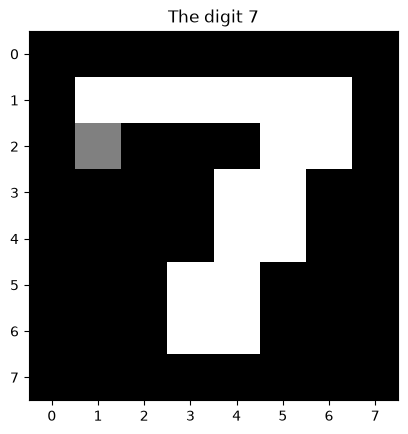

In [66]:
# T10: An image is an array
img = np.zeros((8, 8), dtype=int)       # (a) black 8x8 canvas
img[1, 1:7] = 255                       # top bar of the 7 (white)
img[2, 5:7] = 255                       # bar turns into the stem
img[3, 4:6] = 255
img[4, 4:6] = 255
img[5, 3:5] = 255
img[6, 3:5] = 255
img[2, 1] = 128                         # small grey hook under the left end of the bar
print("T10a:\n", img)

flipped = np.fliplr(img)                # (b) mirror left-right
print("T10b:\n", flipped)

inverted = 255 - img                    # (c) swap light and dark
print("T10c:\n", inverted)

crop = img[1:5, 3:7]                    # (d) rows 1-4, columns 3-6
print("T10d:\n", crop)

bright = np.clip(img + 80, 0, 255)      # (e) brighten, never above 255
print("T10e:\n", bright)

print("T10f: shape =", img.shape, "| dtype =", img.dtype, "| white pixels =", np.sum(img == 255))   # (f)

# Optional picture
import matplotlib.pyplot as plt
plt.imshow(img, cmap="gray")
plt.title("The digit 7")
plt.show()

## Task 11 · Reflection

From the census, I did not know AJK is growing at only about 1.15 % a year while Balochistan is growing at about 3.2 %. From the climate data, Quetta's hottest month is July, not June like Peshawar and Islamabad, and it gets almost no monsoon rain (6 % of its yearly total). From inflation, prices rose by about 26 % on average in FY2024 but only about 5 % in FY2025, and April 2025 was just 0.3 %. The function that saved me the most work was `argmax` with `axis=1`: without it I would have written a loop over the 5 cities, an inner loop over 12 months, and an `if` to keep track of the largest value and its position.